In [1]:
import pandas as pd

df = pd.read_csv("data.csv", encoding = "ISO-8859-1")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [3]:
df.shape

(541909, 8)

In [4]:
df = df.drop(columns = ["Description"], axis = 1)

In [5]:
# Смотрим сколько у нас наблюдений со значением NaN в каждом столбце

print(f"InvoiceNo: {df["InvoiceNo"].isna().sum()}")
print(f"StockCode: {df["StockCode"].isna().sum()}")
print(f"Quantity: {df["Quantity"].isna().sum()}")
print(f"InvoiceDate: {df["InvoiceDate"].isna().sum()}")
print(f"UnitPrice: {df["UnitPrice"].isna().sum()}")
print(f"CustomerID: {df["CustomerID"].isna().sum()}")
print(f"Country: {df["Country"].isna().sum()}")

InvoiceNo: 0
StockCode: 6035
Quantity: 6035
InvoiceDate: 6035
UnitPrice: 6035
CustomerID: 138727
Country: 6035


In [6]:
# Удаляем наблюдения со значениями NaN

df = df[df["StockCode"].isna() == False]
df = df[df["Quantity"].isna() == False]
df = df[df["InvoiceDate"].isna() == False]
df = df[df["UnitPrice"].isna() == False]
df = df[df["InvoiceDate"].isna() == False]
df = df[df["CustomerID"].isna() == False]
df = df[df["Country"].isna() == False]

In [7]:
# Видим, что больше всего уникальных пользователей у нас из
# Великобритании, поэтому мы возьмем эту страну для нашего анализа

df.drop_duplicates(subset = ["CustomerID"]).groupby(by = ["Country"]).count()["CustomerID"].sort_values(ascending = False)

Country
United Kingdom          3948
Germany                   95
France                    87
Spain                     29
Belgium                   24
Switzerland               20
Portugal                  19
Italy                     15
Finland                   12
Norway                    10
Netherlands                9
Austria                    9
Australia                  9
Channel Islands            9
Sweden                     8
Denmark                    8
Japan                      8
Cyprus                     7
Poland                     6
USA                        4
Canada                     4
Unspecified                4
Israel                     4
Greece                     4
EIRE                       3
Malta                      2
United Arab Emirates       2
Bahrain                    2
Czech Republic             1
Lithuania                  1
Lebanon                    1
RSA                        1
Saudi Arabia               1
Singapore                  1
Icelan

In [8]:
df_uk = df[df["Country"] == "United Kingdom"].copy()

In [9]:
df_uk["InvoiceDate"] = pd.to_datetime(df_uk["InvoiceDate"])

In [10]:
df_uk["Year"] = [i.year for i in df_uk["InvoiceDate"]]
df_uk["Month"] = [i.month for i in df_uk["InvoiceDate"]]
df_uk["Day"] = [i.day for i in df_uk["InvoiceDate"]]

In [11]:
df_uk.drop_duplicates(subset = ["CustomerID"]).groupby(by = ["Year"]).count()["CustomerID"].sort_values(ascending = False)

Year
2011    3078
2010     870
Name: CustomerID, dtype: int64

In [12]:
df_uk_eleven = df_uk[df_uk["Year"] == 2011].copy()

In [13]:
df_uk_eleven.shape

(334215, 10)

In [14]:
df_uk_eleven = df_uk_eleven.drop(columns = ["InvoiceDate"])
df_uk_eleven.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,Country,Year,Month,Day
42481,539993,22386,10.0,1.95,13313.0,United Kingdom,2011,1,4
42482,539993,21499,25.0,0.42,13313.0,United Kingdom,2011,1,4
42483,539993,21498,25.0,0.42,13313.0,United Kingdom,2011,1,4
42484,539993,22379,5.0,2.10,13313.0,United Kingdom,2011,1,4
42485,539993,20718,10.0,1.25,13313.0,United Kingdom,2011,1,4


In [15]:
df_uk_eleven.dtypes

InvoiceNo      object
StockCode      object
Quantity      float64
UnitPrice     float64
CustomerID    float64
Country        object
Year            int64
Month           int64
Day             int64
dtype: object

In [16]:
df_uk_eleven = df_uk_eleven.drop(df_uk_eleven[df_uk_eleven["Quantity"] < 0].index)

In [17]:
df_uk_eleven = df_uk_eleven.drop(df_uk_eleven[df_uk_eleven["UnitPrice"] < 0].index)

In [18]:
12 - df_uk_eleven.groupby(by = ["CustomerID"])["Month"].max()

CustomerID
12346.0    11
12747.0     0
12748.0     0
12749.0     0
12820.0     0
           ..
18280.0     9
18281.0     6
18282.0     0
18283.0     0
18287.0     2
Name: Month, Length: 3813, dtype: int64

In [19]:
rfm_df = pd.DataFrame(data = {
    "CustomerID": df_uk_eleven.groupby(by = ["CustomerID"])["Month"].max().index,
    "R": 12 - df_uk_eleven.groupby(by = ["CustomerID"])["Month"].max().values})

In [20]:
rfm_df = rfm_df.set_index("CustomerID")

In [21]:
recency_cats = []

for i in rfm_df["R"].values:

    if i > 6:
        recency_cats.append(3)

    if 2 <= i <= 6:
        recency_cats.append(2)

    if i < 2:
        recency_cats.append(1)

rfm_df["R"] = recency_cats

In [22]:
search_f = df_uk_eleven.groupby(by = ["CustomerID"])["Month"].agg(["min", "max"])

search_f["purchase"] = df_uk_eleven.drop_duplicates(subset = ["InvoiceNo"]).groupby(by = ["CustomerID"])["InvoiceNo"].count()

search_f["life_dist"] = search_f["max"] - search_f["min"] + 1

search_f["buy_per_month"] = search_f["purchase"] / search_f["life_dist"]

search_f

,min,max,purchase,life_dist,buy_per_month
CustomerID,,,,,
12346.0,1,1,1,1,1.000000
12747.0,1,12,9,12,0.750000
12748.0,1,12,175,12,14.583333
12749.0,5,12,5,8,0.625000
12820.0,1,12,4,12,0.333333
...,...,...,...,...,...
18280.0,3,3,1,1,1.000000
18281.0,6,6,1,1,1.000000
18282.0,8,12,2,5,0.400000


In [23]:
(search_f["buy_per_month"].max() - search_f["buy_per_month"].min()) / 3

4.800505050505051

In [24]:
frequency_cats = []

for i in search_f["buy_per_month"].values:

    if i > 10:
        frequency_cats.append(1)

    if 5 <= i <= 10:
        frequency_cats.append(2)

    if i < 5:
        frequency_cats.append(3)

rfm_df["F"] = frequency_cats

In [25]:
df_uk_eleven["TotalPrice"] = df_uk_eleven["Quantity"] * df_uk_eleven["UnitPrice"]

In [26]:
search_f["summary"] = df_uk_eleven.groupby(by = ["CustomerID"])["TotalPrice"].sum()

search_f["av_sum"] = search_f["summary"] / search_f["purchase"]

search_f["av_sum"].quantile(0.25)

172.9

In [27]:
monetary_cats = []

for i in search_f["av_sum"].values:

    if i > search_f["av_sum"].quantile(0.75):
        monetary_cats.append(1)

    if search_f["av_sum"].quantile(0.25) <= i <= search_f["av_sum"].quantile(0.75):
        monetary_cats.append(2)

    if i < search_f["av_sum"].quantile(0.25):
        monetary_cats.append(3)

rfm_df["M"] = monetary_cats

In [28]:
r = rfm_df["R"].values
f = rfm_df["F"].values
m = rfm_df["M"].values

names = []

for i in range(0, len(r)):
    names.append(f"{r[i]}{f[i]}{m[i]}")

rfm_df["cat_name"] = names

In [29]:
rfm_df

,R,F,M,cat_name
CustomerID,,,,
12346.0,3,3,1,331
12747.0,1,3,2,132
12748.0,1,1,3,113
12749.0,1,3,1,131
12820.0,1,3,2,132
...,...,...,...,...
18280.0,3,3,2,332
18281.0,2,3,3,233
18282.0,1,3,3,133


In [30]:
rfm_df.reset_index().groupby(by = ["cat_name"]).count()["CustomerID"].sort_values(ascending = False)

cat_name
132    941
232    710
131    441
233    388
231    386
133    331
332    255
333    231
331    120
121      5
123      2
113      1
122      1
221      1
Name: CustomerID, dtype: int64

In [31]:
rfm_df["last_buy"] = 12 - df_uk_eleven.groupby(by = ["CustomerID"])["Month"].max().values
rfm_df["purchase_per_month"] = search_f["buy_per_month"]
rfm_df["av_sum"] = search_f["av_sum"]

In [32]:
new_rfm_df = rfm_df[rfm_df["av_sum"] < 1000]

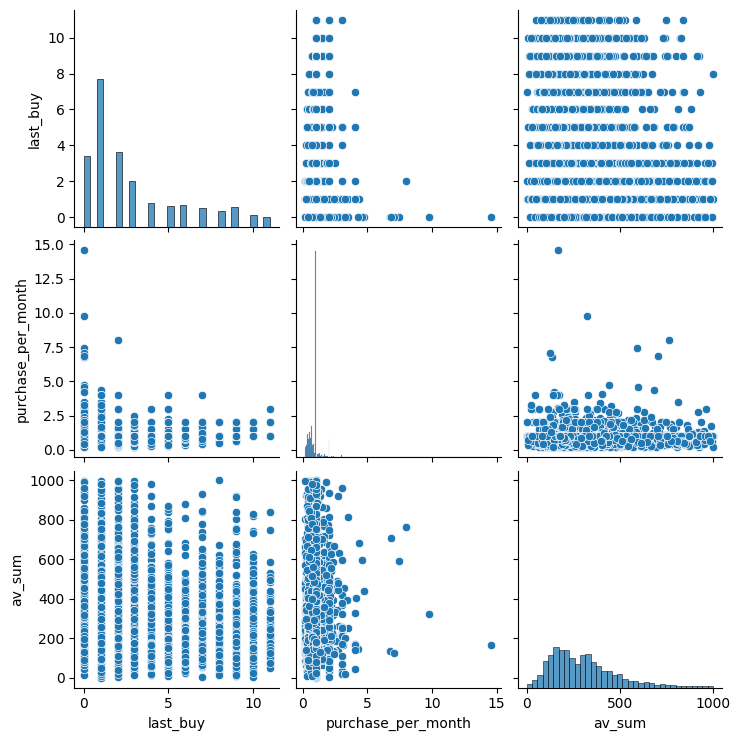

In [33]:
import seaborn as sns

sns.pairplot(new_rfm_df[["last_buy", "purchase_per_month", "av_sum"]])

In [36]:
lbuy = rfm_df["last_buy"].values
pur_per_m = rfm_df["purchase_per_month"].values
mean_sum = rfm_df["av_sum"].values

In [35]:
a

array([11,  0,  0, ...,  0,  0,  2])

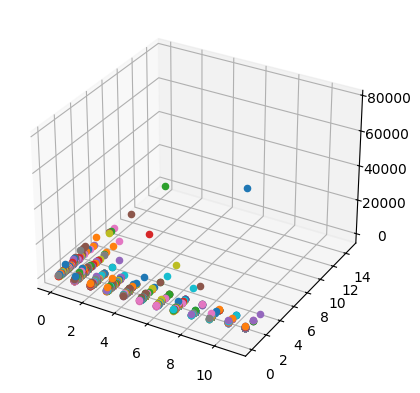

In [37]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection = "3d")

for i in range(len(lbuy)):
    ax.scatter(lbuy[i], pur_per_m[i], mean_sum[i])

plt.show()

# Вывод

Наиболее многочисленная выборка у нас -- это "недавние разовые со средним чеком". Бизнес следует придумать способы как привлечь клиентов повторно в ближашее время